# 🌼 Flower Classification – End-to-End ML Pipeline
**Dataset:** TF Flowers (≈3,670 real photos, 5 classes). **Model:** MobileNetV2 transfer learning.

Sections: 1 Data acquisition · 2 EDA & visualisations · 3 Preprocessing · 4 Baseline CNN · 5 Optimised model · 6 Evaluation · 7 Save model & prediction function · 8 Retraining demo

> Run top-to-bottom (Kernel → Restart & Run All) and **commit the notebook with outputs**.

In [4]:
!git clone https://github.com/sammyn11/flower_mlops.git /content/flower_mlops

Cloning into '/content/flower_mlops'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 34 (delta 1), reused 34 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 27.73 KiB | 3.96 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [5]:
import os, sys, json, random
from pathlib import Path
# In Colab, first upload/extract the repository ZIP under /content or clone it there.
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/flower_mlops')]
if Path('/content').exists(): candidates += [p.parent.parent for p in Path('/content').rglob('config.py') if p.parent.name == 'src']
ROOT = next((p.resolve() for p in candidates if (p / 'src' / 'config.py').exists()), None)
if ROOT is None: raise FileNotFoundError('Project source not found. In Colab, upload/extract the flower_mlops repository ZIP under /content, then rerun.')
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report

from src import config as C, preprocessing as P, model as M
from src.insights import compute_insights

tf.keras.utils.set_random_seed(C.SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [6]:
import tensorflow as tf

In [7]:
P.download_and_split()

Split complete.


## 1. Data acquisition
The dataset is downloaded from the TensorFlow public bucket and split **80/20 per class** into `data/train` and `data/test` (the test set is never used for training or tuning).

In [8]:
P.download_and_split()
class_names = P.get_class_names(C.TRAIN_DIR)
print("Classes:", class_names)
for split in (C.TRAIN_DIR, C.TEST_DIR):
    print(split.name, {c: len(list((split/c).glob('*'))) for c in class_names})

Train/test folders already populated - skipping download.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train {'daisy': 507, 'dandelion': 719, 'roses': 513, 'sunflowers': 560, 'tulips': 640}
test {'daisy': 126, 'dandelion': 179, 'roses': 128, 'sunflowers': 139, 'tulips': 159}


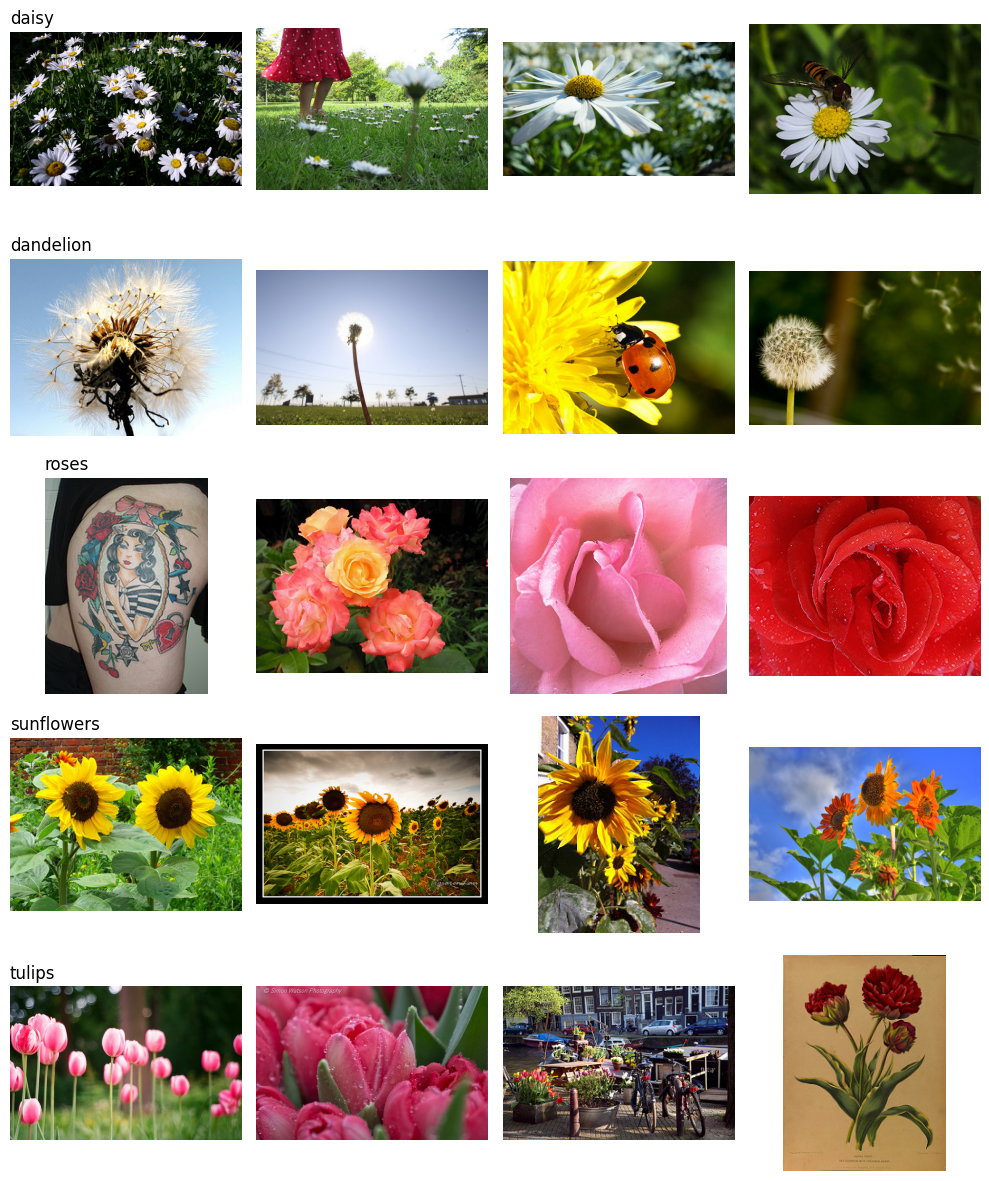

In [9]:
# A look at the raw data
fig, axes = plt.subplots(len(class_names), 4, figsize=(10, 2.4*len(class_names)))
for i, c in enumerate(class_names):
    files = random.sample(list((C.TRAIN_DIR/c).glob('*.jpg')), 4)
    for j, f in enumerate(files):
        axes[i, j].imshow(plt.imread(f)); axes[i, j].axis('off')
        if j == 0: axes[i, j].set_title(c, loc='left')
plt.tight_layout(); plt.show()

## 2. Exploratory data analysis (3+ features, with interpretation)

In [10]:
ins = compute_insights(per_class_sample=100)

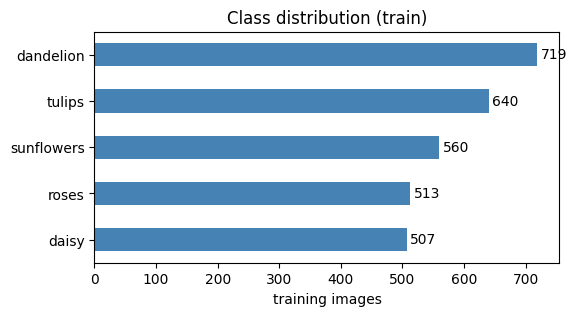

Imbalance ratio largest/smallest: 1.42


In [11]:
# Feature 1: class distribution
counts = pd.Series(ins['class_counts']['train']).sort_values()
ax = counts.plot.barh(figsize=(6,3), color='steelblue'); ax.set_xlabel('training images')
for i, v in enumerate(counts): ax.text(v+5, i, str(v), va='center')
plt.title('Class distribution (train)'); plt.show()
print(f"Imbalance ratio largest/smallest: {counts.max()/counts.min():.2f}")

**Interpretation 1 – Class distribution.** The classes are *mildly* imbalanced (largest/smallest ≈ 1.4×, see printed ratio). Not severe enough to need resampling, but it means accuracy alone can hide weak performance on the smaller classes, so we report **per-class precision/recall/F1** and a confusion matrix.

/tmp/ipykernel_626/360914006.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([ins['brightness'][c] for c in class_names], labels=class_names)


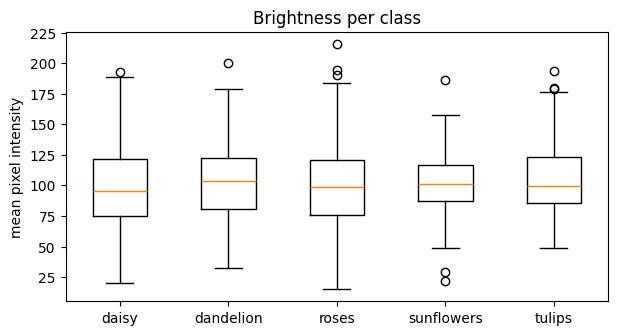

daisy          95.4
dandelion     103.8
roses          99.1
sunflowers    100.9
tulips         99.3
dtype: float64


In [12]:
# Feature 2: brightness per class
plt.figure(figsize=(7,3.5))
plt.boxplot([ins['brightness'][c] for c in class_names], labels=class_names)
plt.ylabel('mean pixel intensity'); plt.title('Brightness per class'); plt.show()
print(pd.Series({c: np.median(v) for c, v in ins['brightness'].items()}).round(1))

**Interpretation 2 – Brightness.** *(Read the plot and complete this sentence with your numbers, e.g. which class is brightest/darkest and how wide the spread is.)* Overlapping boxes mean brightness alone cannot discriminate classes, and wide spreads (mixed sun/shade photos) justify the contrast augmentation used in preprocessing.

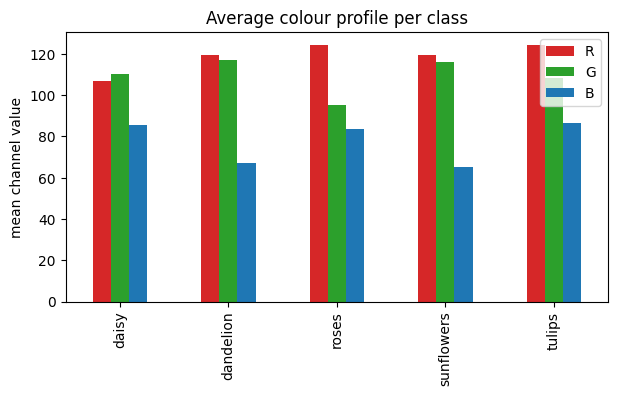

daisy         0.353
tulips        0.389
dandelion     0.394
sunflowers    0.397
roses         0.410
dtype: float64


In [13]:
# Feature 3: average colour profile
rgb = pd.DataFrame(ins['rgb_mean'], index=['R','G','B']).T
rgb.plot.bar(color=['tab:red','tab:green','tab:blue'], figsize=(7,3.5)); plt.ylabel('mean channel value')
plt.title('Average colour profile per class'); plt.show()
print((rgb['R']/rgb.sum(axis=1)).round(3).sort_values())

**Interpretation 3 – Colour.** All classes are green-dominant (leaves/stems in the background). The class with the highest red share is the most “colour-distinctive”; classes with similar profiles are the ones we expect to be confused (check the confusion matrix later). Colour helps, but shape/texture features learned by the CNN are needed.

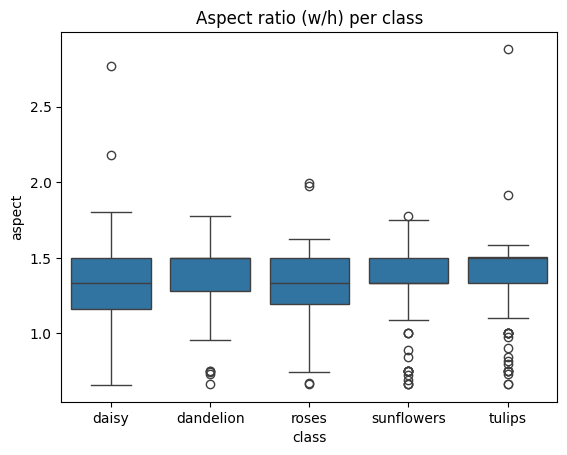

            w       h  aspect
count  500.00  500.00  500.00
mean   365.26  272.39    1.33
std    114.95   53.70    0.28
min    158.00  200.00    0.66
25%    320.00  240.00    1.26
50%    320.00  240.00    1.33
75%    500.00  333.00    1.50
max    640.00  429.00    2.88


In [14]:
# Feature 4: image dimensions
rows = [(c, w, h, w/h) for c, s in ins['size'].items() for w, h in s]
sz = pd.DataFrame(rows, columns=['class','w','h','aspect'])
sns.boxplot(data=sz, x='class', y='aspect'); plt.title('Aspect ratio (w/h) per class'); plt.show()
print(sz[['w','h','aspect']].describe().round(2))

**Interpretation 4 – Image size.** Images are not uniform and mostly not square, so every image must be resized to a fixed 224×224 (MobileNetV2 input). This stretches some images slightly; centre-crop/padding is a possible improvement.

## 3. Data preprocessing
1. Stratified **85/15 train/validation split** of `data/train` (test set stays untouched)
2. Decode → **resize to 224×224** → batch(32) with `tf.data`
3. **Augmentation (training only):** horizontal flip, rotation ±10 %, zoom ±10 %, contrast ±10 %
4. **Normalisation:** pixels scaled to [-1, 1] by a `Rescaling` layer *inside* the model, so the API receives raw pixels and cannot diverge from training

train=2500  val=439


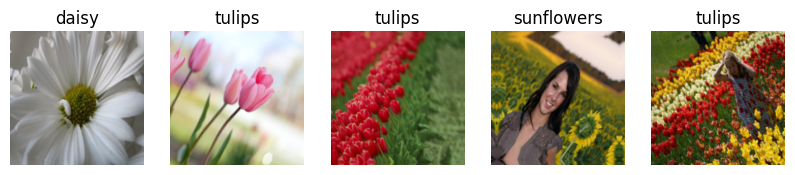

In [15]:
paths, labels = P.list_files(C.TRAIN_DIR, class_names)
(tp, tl), (vp, vl) = P.stratified_split(paths, labels, 0.15)
n = len(class_names)
train_ds = P.paths_to_dataset(tp, tl, n, training=True)
val_ds   = P.paths_to_dataset(vp, vl, n)
print(f"train={len(tp)}  val={len(vp)}")

# show augmentation on one image
x, y = next(iter(train_ds))
plt.figure(figsize=(10,2.5))
for i in range(5):
    plt.subplot(1,5,i+1); plt.imshow(x[i].numpy().astype('uint8')); plt.title(class_names[y[i].numpy().argmax()]); plt.axis('off')
plt.show()

## 4. Baseline: small CNN from scratch (no pre-training)

In [16]:
from tensorflow.keras import layers
baseline = tf.keras.Sequential([
    layers.Input((*C.IMG_SIZE, 3)), layers.Rescaling(1/255),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dense(n, activation='softmax')
], name='baseline_cnn')
M.compile_model(baseline, 1e-3)
h_base = baseline.fit(train_ds, validation_data=val_ds, epochs=10, verbose=2,
                      callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

Epoch 1/10
79/79 - 346s - 4s/step - accuracy: 0.4192 - loss: 1.4743 - val_accuracy: 0.5216 - val_loss: 1.1365
Epoch 2/10
79/79 - 329s - 4s/step - accuracy: 0.5852 - loss: 1.0526 - val_accuracy: 0.5718 - val_loss: 1.0845
Epoch 3/10
79/79 - 329s - 4s/step - accuracy: 0.6272 - loss: 0.9632 - val_accuracy: 0.6424 - val_loss: 0.9585
Epoch 4/10
79/79 - 327s - 4s/step - accuracy: 0.6488 - loss: 0.9122 - val_accuracy: 0.6446 - val_loss: 0.9365
Epoch 5/10
79/79 - 322s - 4s/step - accuracy: 0.6864 - loss: 0.8322 - val_accuracy: 0.6196 - val_loss: 0.9807
Epoch 6/10
79/79 - 327s - 4s/step - accuracy: 0.7092 - loss: 0.7834 - val_accuracy: 0.6856 - val_loss: 0.8320
Epoch 7/10
79/79 - 327s - 4s/step - accuracy: 0.7232 - loss: 0.7450 - val_accuracy: 0.6651 - val_loss: 0.8698
Epoch 8/10
79/79 - 321s - 4s/step - accuracy: 0.7480 - loss: 0.6838 - val_accuracy: 0.6651 - val_loss: 0.8394
Epoch 9/10
79/79 - 322s - 4s/step - accuracy: 0.7248 - loss: 0.7055 - val_accuracy: 0.6333 - val_loss: 0.8991


## 5. Optimised model: MobileNetV2 transfer learning
Optimisation techniques used: **pre-trained model**, **L2 regularisation**, **Dropout**, **Adam optimiser** with a tuned learning rate, **EarlyStopping**, **ReduceLROnPlateau**, **two-phase fine-tuning**, plus **data augmentation** and a small **hyper-parameter search**.
### 5a. Hyper-parameter search (head learning rate × dropout, 3 epochs each)

In [17]:
results = []
for lr in (1e-3, 3e-4):
    for dr in (0.2, 0.4):
        m = M.build_model(n, dropout=dr); M.compile_model(m, lr)
        h = m.fit(train_ds, validation_data=val_ds, epochs=3, verbose=0)
        results.append({'lr': lr, 'dropout': dr, 'val_acc': max(h.history['val_accuracy']), 'val_loss': min(h.history['val_loss'])})
tune = pd.DataFrame(results).sort_values('val_acc', ascending=False); display(tune)
best = tune.iloc[0]; print('Best:', dict(best))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


,lr,dropout,val_acc,val_loss
1,0.0010,0.4,0.861048,0.400205
0,0.0010,0.2,0.858770,0.416426
2,0.0003,0.2,0.820046,0.548916
3,0.0003,0.4,0.813212,0.553345


Best: {'lr': np.float64(0.001), 'dropout': np.float64(0.4), 'val_acc': np.float64(0.8610478639602661), 'val_loss': np.float64(0.4002046585083008)}


### 5b. Phase 1 – train the head (base frozen) with the best settings

In [18]:
model = M.build_model(n, dropout=float(best.dropout)); M.compile_model(model, float(best.lr))
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=M.make_callbacks(), verbose=2)

Epoch 1/10
79/79 - 164s - 2s/step - accuracy: 0.6228 - loss: 1.0148 - val_accuracy: 0.8132 - val_loss: 0.5263 - learning_rate: 0.0010
Epoch 2/10
79/79 - 154s - 2s/step - accuracy: 0.7960 - loss: 0.5582 - val_accuracy: 0.8565 - val_loss: 0.4212 - learning_rate: 0.0010
Epoch 3/10
79/79 - 157s - 2s/step - accuracy: 0.8400 - loss: 0.4585 - val_accuracy: 0.8610 - val_loss: 0.4013 - learning_rate: 0.0010
Epoch 4/10
79/79 - 155s - 2s/step - accuracy: 0.8508 - loss: 0.4294 - val_accuracy: 0.8428 - val_loss: 0.4121 - learning_rate: 0.0010
Epoch 5/10
79/79 - 157s - 2s/step - accuracy: 0.8688 - loss: 0.3738 - val_accuracy: 0.8565 - val_loss: 0.3847 - learning_rate: 0.0010
Epoch 6/10
79/79 - 156s - 2s/step - accuracy: 0.8720 - loss: 0.3542 - val_accuracy: 0.8656 - val_loss: 0.3773 - learning_rate: 0.0010
Epoch 7/10
79/79 - 155s - 2s/step - accuracy: 0.8796 - loss: 0.3398 - val_accuracy: 0.8656 - val_loss: 0.3695 - learning_rate: 0.0010
Epoch 8/10
79/79 - 155s - 2s/step - accuracy: 0.8828 - loss: 0

### 5c. Phase 2 – fine-tune the top 30 MobileNetV2 layers at a low learning rate

In [19]:
M.unfreeze_top(model, 30); M.compile_model(model, 1e-5)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=M.make_callbacks(), verbose=2)

Epoch 1/10
79/79 - 195s - 2s/step - accuracy: 0.8952 - loss: 0.2934 - val_accuracy: 0.8861 - val_loss: 0.3302 - learning_rate: 1.0000e-05
Epoch 2/10
79/79 - 184s - 2s/step - accuracy: 0.9048 - loss: 0.2688 - val_accuracy: 0.8838 - val_loss: 0.3185 - learning_rate: 1.0000e-05
Epoch 3/10
79/79 - 186s - 2s/step - accuracy: 0.9152 - loss: 0.2384 - val_accuracy: 0.8952 - val_loss: 0.2948 - learning_rate: 1.0000e-05
Epoch 4/10
79/79 - 185s - 2s/step - accuracy: 0.9236 - loss: 0.2078 - val_accuracy: 0.8998 - val_loss: 0.2898 - learning_rate: 1.0000e-05
Epoch 5/10
79/79 - 183s - 2s/step - accuracy: 0.9376 - loss: 0.1851 - val_accuracy: 0.9043 - val_loss: 0.2782 - learning_rate: 1.0000e-05
Epoch 6/10
79/79 - 184s - 2s/step - accuracy: 0.9324 - loss: 0.1781 - val_accuracy: 0.9021 - val_loss: 0.2880 - learning_rate: 1.0000e-05
Epoch 7/10
79/79 - 185s - 2s/step - accuracy: 0.9380 - loss: 0.1680 - val_accuracy: 0.9089 - val_loss: 0.2788 - learning_rate: 1.0000e-05
Epoch 8/10
79/79 - 186s - 2s/step 

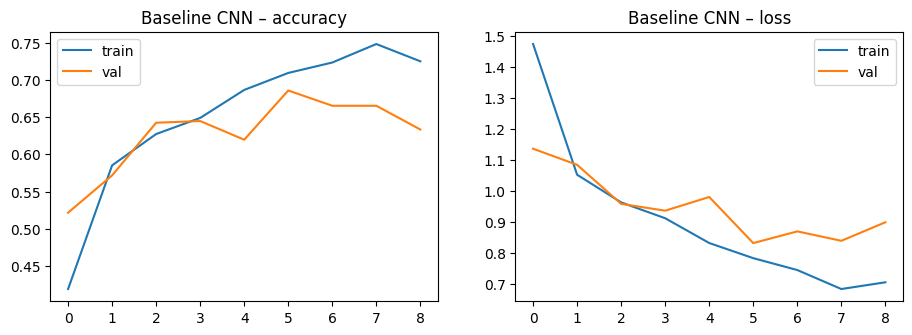

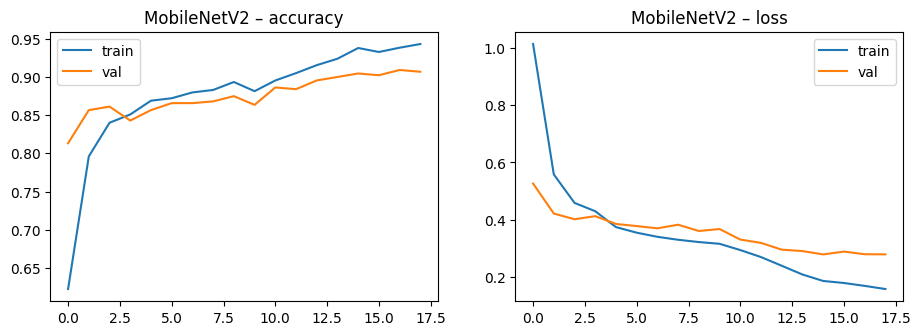

In [20]:
def curves(histories, title):
    acc = sum([h.history['accuracy'] for h in histories], []);     vacc = sum([h.history['val_accuracy'] for h in histories], [])
    loss = sum([h.history['loss'] for h in histories], []);        vloss = sum([h.history['val_loss'] for h in histories], [])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(acc, label='train'); ax[0].plot(vacc, label='val'); ax[0].set_title(title+' – accuracy'); ax[0].legend()
    ax[1].plot(loss, label='train'); ax[1].plot(vloss, label='val'); ax[1].set_title(title+' – loss'); ax[1].legend()
    plt.show()
curves([h_base], 'Baseline CNN'); curves([h1, h2], 'MobileNetV2')

## 6. Evaluation on the held-out test set (accuracy, loss, precision, recall, F1, confusion matrix)

In [21]:
m_base, _, _ = M.evaluate_model(baseline, class_names)
m_opt, y_true, y_pred = M.evaluate_model(model, class_names)
keys = ['accuracy','loss','precision','recall','f1']
cmp = pd.DataFrame({'Baseline CNN': {k: m_base[k] for k in keys}, 'MobileNetV2 (optimised)': {k: m_opt[k] for k in keys}}).round(4)
display(cmp)

,Baseline CNN,MobileNetV2 (optimised)
accuracy,0.6772,0.9042
loss,0.8292,0.3121
precision,0.6909,0.9032
recall,0.6668,0.9060
f1,0.6722,0.9041


              precision    recall  f1-score   support

       daisy      0.905     0.905     0.905       126
   dandelion      0.935     0.877     0.905       179
       roses      0.891     0.898     0.895       128
  sunflowers      0.881     0.957     0.917       139
      tulips      0.904     0.893     0.899       159

    accuracy                          0.904       731
   macro avg      0.903     0.906     0.904       731
weighted avg      0.905     0.904     0.904       731



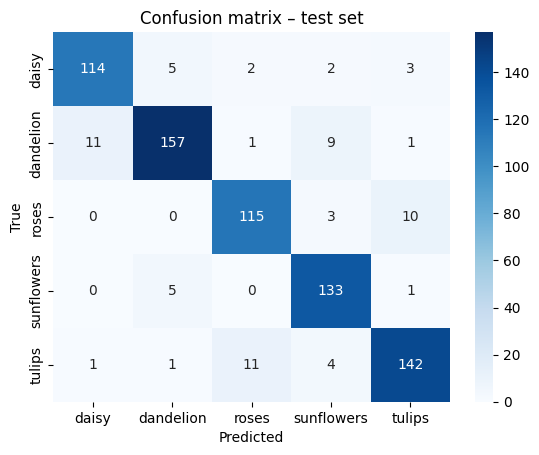

In [22]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = np.array(m_opt['confusion_matrix'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix – test set'); plt.show()

**Discussion.** *(Complete with your numbers.)* The pre-trained, regularised model should clearly beat the scratch CNN because ImageNet features transfer well to flowers and the dataset is small. Use the confusion matrix to name the most-confused pair of classes and connect it to the colour/brightness findings in Section 2.

## 7. Save the model + prediction function

In [23]:
version = M.save_artifacts(model, class_names, m_opt, 'notebook_training')
print('Saved', C.MODEL_PATH, 'as version', version)

Saved /content/flower_mlops/models/flower_model.h5 as version 1


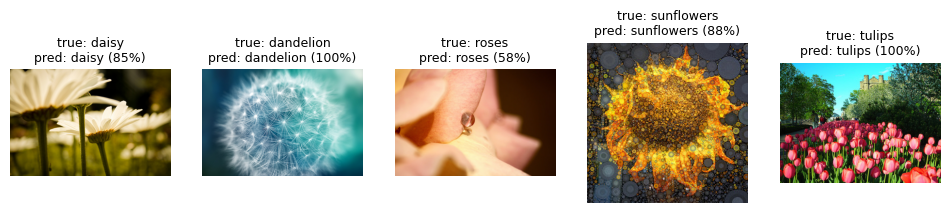

In [24]:
from src.prediction import predict_image
test_files = [f for c in class_names for f in random.sample(list((C.TEST_DIR/c).glob('*.jpg')), 1)]
plt.figure(figsize=(12,3))
for i, f in enumerate(test_files):
    r = predict_image(f.read_bytes())
    plt.subplot(1, len(test_files), i+1); plt.imshow(plt.imread(f)); plt.axis('off')
    plt.title(f"true: {f.parent.name}\npred: {r['label']} ({r['confidence']:.0%})", fontsize=9)
plt.show()

In [25]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [26]:
from pathlib import Path
import shutil

source = Path("/content/flower_mlops/models")
destination = Path("/content/drive/MyDrive/flower_mlops/models")
destination.mkdir(parents=True, exist_ok=True)

for name in ["flower_model.h5", "class_names.json", "model_meta.json"]:
    shutil.copy2(source / name, destination / name)

print("Saved files:", [p.name for p in destination.iterdir()])

Saved files: ['flower_model.h5', 'class_names.json', 'model_meta.json']


## 8. Retraining demo
`M.retrain()` loads **our saved model** (`models/flower_model.h5`) as the pre-trained base, merges *uploaded* images (`data/uploads/`) with a replay sample of the original data, fine-tunes at a low learning rate, re-evaluates, and saves a new version. In production this is triggered from the UI/API (`POST /retrain`) or automatically at 50 pending uploads.

To demo it here, simulate an upload using a few images through the same preprocessing function the API uses:

In [27]:
RUN_RETRAIN_DEMO = True
if RUN_RETRAIN_DEMO:
    for c in class_names:
        for f in random.sample(list((C.TRAIN_DIR/c).glob('*.jpg')), 10):
            P.save_uploaded_image(f.read_bytes(), f.name, c)
    meta = M.retrain(epochs=3)
    print(meta['latest']['metrics']['accuracy'], 'vs before', meta['latest']['accuracy_before'])

[loading] loading existing model flower_model.h5 as the pre-trained base


[loading] current model test accuracy = 0.9042
[preprocessing] 50 uploaded images (already validated, resized to 224x224 and stored at upload time)
[preprocessing] combined set: 50 new + 200 replay -> 215 train / 35 validation
[training] fine-tuning for up to 3 epochs (lr=1e-05)
[training] epoch 1: loss=0.2734 acc=0.9163 val_loss=0.2668 val_acc=0.9143
[training] epoch 2: loss=0.1986 acc=0.9116 val_loss=0.3010 val_acc=0.9143
[training] epoch 3: loss=0.2158 acc=0.9116 val_loss=0.2386 val_acc=0.9143
[evaluating] evaluating retrained model on held-out test set


[done] saved model v2: accuracy 0.9042 -> 0.8892
0.8891928864569083 vs before 0.9042407660738714


In [28]:
from pathlib import Path
import shutil

source = Path("/content/flower_mlops/models")
destination = Path("/content/drive/MyDrive/flower_mlops/models")
destination.mkdir(parents=True, exist_ok=True)

for name in ["flower_model.h5", "class_names.json", "model_meta.json"]:
    shutil.copy2(source / name, destination / name)

print("Saved files:", [p.name for p in destination.iterdir()])

Saved files: ['flower_model.h5', 'class_names.json', 'model_meta.json']
